# Concentration prior type of the variational Bayesian Gaussian mixture: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/mixture/plot_concentration_prior.py`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/mixture/plot_concentration_prior.html))
at scikit-learn `4358542a1bd39af2e7e1cbace8b9fed067473c5b`.

**Scenario:** 900 points from three 2-D Gaussians (`np.random.RandomState(2)`). One
`BayesianGaussianMixture(n_components=6, reg_covar=0, init_params="random", max_iter=1500,
mean_precision_prior=0.8, random_state=2)` per weight prior type (`dirichlet_distribution`,
`dirichlet_process`) is refitted for three `weight_concentration_prior` values each, by assigning the
attribute and calling `fit` again, exactly as the example does.

**Beyond the gallery:** all variational posterior attributes (`weight_concentration_`, `mean_precision_`,
`degrees_of_freedom_`, `precisions_cholesky_`), resolved priors (`mean_prior_`, `covariance_prior_`,
`degrees_of_freedom_prior_`), `lower_bound_`, `n_iter_`, `converged_`, `predict`, `predict_proba`,
`score_samples`, `score`, `sample`, and `clone` of a fitted model.

**Adaptations:**
- The data is generated by the official code in Python and shared.
- sklearn's `weight_concentration_` is a tuple `(a, b)` for the Dirichlet process and an array for the
  Dirichlet distribution; Moxie returns a `List` of two arrays or one array (`docs/mixture/bayesian/api.md`).
- `sample` coordinates of a full-covariance component come from an SVD factor whose orientation may
  differ from NumPy's LAPACK one (`docs/mixture/README.md`); component labels and the Mahalanobis norms of
  the draws are compared instead of raw coordinates.

**Determinism:** deterministic (seeded MT19937, `init_params="random"` draws uniforms only). All learned
values are compared numerically.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("mixture/plot_concentration_prior")

## 1. scikit-learn (Python reference)

In [2]:
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np

from sklearn.base import clone
from sklearn.mixture import BayesianGaussianMixture


def plot_ellipses(ax, weights, means, covars):
    for n in range(means.shape[0]):
        eig_vals, eig_vecs = np.linalg.eigh(covars[n])
        unit_eig_vec = eig_vecs[0] / np.linalg.norm(eig_vecs[0])
        angle = np.arctan2(unit_eig_vec[1], unit_eig_vec[0])
        angle = 180 * angle / np.pi
        eig_vals = 2 * np.sqrt(2) * np.sqrt(eig_vals)
        ell = mpl.patches.Ellipse(
            means[n], eig_vals[0], eig_vals[1], angle=180 + angle, edgecolor="black"
        )
        ell.set_clip_box(ax.bbox)
        ell.set_alpha(weights[n])
        ell.set_facecolor("#56B4E9")
        ax.add_artist(ell)


random_state, n_components, n_features = 2, 3, 2
colors = np.array(["#0072B2", "#F0E442", "#D55E00"])
covars = np.array(
    [[[0.7, 0.0], [0.0, 0.1]], [[0.5, 0.0], [0.0, 0.1]], [[0.5, 0.0], [0.0, 0.1]]]
)
samples = np.array([200, 500, 200])
means = np.array([[0.0, -0.70], [0.0, 0.0], [0.0, 0.70]])

estimators = [
    ("dirichlet_distribution",
     BayesianGaussianMixture(weight_concentration_prior_type="dirichlet_distribution",
                             n_components=2 * n_components, reg_covar=0, init_params="random",
                             max_iter=1500, mean_precision_prior=0.8, random_state=random_state),
     [0.001, 1, 1000]),
    ("dirichlet_process",
     BayesianGaussianMixture(weight_concentration_prior_type="dirichlet_process",
                             n_components=2 * n_components, reg_covar=0, init_params="random",
                             max_iter=1500, mean_precision_prior=0.8, random_state=random_state),
     [1, 1000, 100000]),
]

rng = np.random.RandomState(random_state)
X = np.vstack(
    [rng.multivariate_normal(means[j], covars[j], samples[j]) for j in range(n_components)]
)
y = np.concatenate([np.full(samples[j], j, dtype=int) for j in range(n_components)])
T = X[::7] + 0.05

sk = {}
for kind, estimator, concentrations_prior in estimators:
    for k, concentration in enumerate(concentrations_prior):
        estimator.weight_concentration_prior = concentration
        estimator.fit(X)
        wc = estimator.weight_concentration_
        sk[(kind, k)] = dict(
            weights=estimator.weights_, means=estimator.means_, cov=estimator.covariances_,
            prec_chol=estimator.precisions_cholesky_, lower_bound=estimator.lower_bound_,
            n_iter=estimator.n_iter_, converged=estimator.converged_,
            wc=np.vstack(wc) if isinstance(wc, tuple) else wc[np.newaxis, :],
            mean_precision=estimator.mean_precision_, dof=estimator.degrees_of_freedom_,
            mean_prior=estimator.mean_prior_, cov_prior=estimator.covariance_prior_,
            dof_prior=estimator.degrees_of_freedom_prior_,
            pred=estimator.predict(X), proba=estimator.predict_proba(T),
            score_samples=estimator.score_samples(T), score=estimator.score(T))
        print(f"{kind:22s} prior={concentration:<8g} n_iter_={estimator.n_iter_:4d} "
              f"lower_bound_={estimator.lower_bound_:.10f} weights_={np.round(estimator.weights_, 3)}")
last = estimators[1][1]
points, labels = last.sample(300)
fresh = clone(last)
print("clone fitted:", hasattr(fresh, "weights_"), "prior kept:", fresh.weight_concentration_prior)
nb.share(X=X, T=T)

dirichlet_distribution prior=0.001    n_iter_= 979 lower_bound_=-45.5339454418 weights_=[0.    0.    0.    0.003 0.    0.997]


dirichlet_distribution prior=1        n_iter_= 731 lower_bound_=-107.4814182590 weights_=[0.001 0.246 0.001 0.401 0.001 0.349]


dirichlet_distribution prior=1000     n_iter_= 541 lower_bound_=-10878.3691865404 weights_=[0.167 0.167 0.167 0.167 0.167 0.167]


dirichlet_process      prior=1        n_iter_= 726 lower_bound_=-82.2732935387 weights_=[0.998 0.001 0.001 0.001 0.    0.   ]


dirichlet_process      prior=1000     n_iter_= 741 lower_bound_=-1424.2894499854 weights_=[0.001 0.844 0.001 0.151 0.001 0.001]


dirichlet_process      prior=100000   n_iter_= 734 lower_bound_=-5281.7578327022 weights_=[0.001 0.246 0.001 0.401 0.001 0.349]
clone fitted: False prior kept: 100000


## 2. Moxie (native Mojo)

The same two estimators; each is refitted after assigning `weight_concentration_prior`.

In [3]:
%%mojo concentration_prior
from numojo import NDArray
from moxie.base import clone
from moxie.mixture import BayesianGaussianMixture
from moxie_nb_io import load, save, save_floats


def run(kind: String, var model: BayesianGaussianMixture[DType.float64], priors: List[Float64],
        X: NDArray[DType.float64], T: NDArray[DType.float64], sample_last: Bool) raises:
    for k in range(len(priors)):
        model.weight_concentration_prior = priors[k]
        _ = model.fit(X)
        var tag = kind + String(k)
        save("weights" + tag, model.weights_)
        save("means" + tag, model.means_)
        save("cov" + tag, model.covariances_)
        save("prec_chol" + tag, model.precisions_cholesky_)
        for part in range(len(model.weight_concentration_)):
            save("wc" + tag + "_" + String(part), model.weight_concentration_[part])
        save("mean_precision" + tag, model.mean_precision_)
        save("dof" + tag, model.degrees_of_freedom_)
        save("mean_prior" + tag, model.mean_prior_)
        save("cov_prior" + tag, model.covariance_prior_)
        save_floats("dof_prior" + tag, [model.degrees_of_freedom_prior_])
        save_floats("lower_bound" + tag, [model.lower_bound_])
        save_floats("n_iter" + tag, [Float64(model.n_iter_)])
        save_floats("converged" + tag, [1.0 if model.converged_ else 0.0])
        save("pred" + tag, model.predict(X))
        save("proba" + tag, model.predict_proba(T))
        save("score_samples" + tag, model.score_samples(T))
        save_floats("score" + tag, [model.score(T)])
        print(kind, "prior=", priors[k], "n_iter_=", model.n_iter_, "lower_bound_=", model.lower_bound_)
    if sample_last:
        var drawn = model.sample(300)
        save("sample_points", drawn[0])
        save("sample_labels", drawn[1])
        var fresh = clone(model)
        print("clone fitted:", fresh.__sklearn_is_fitted__(), "prior kept:", fresh.weight_concentration_prior.value())
        save_floats("clone_fitted", [1.0 if fresh.__sklearn_is_fitted__() else 0.0])


def main() raises:
    var X = load("X")
    var T = load("T")
    var dd = BayesianGaussianMixture[DType.float64](
        weight_concentration_prior_type="dirichlet_distribution", n_components=6, reg_covar=0,
        init_params="random", max_iter=1500, mean_precision_prior=0.8, random_state=2)
    run("dirichlet_distribution", dd^, [0.001, 1.0, 1000.0], X, T, False)
    var dp = BayesianGaussianMixture[DType.float64](
        weight_concentration_prior_type="dirichlet_process", n_components=6, reg_covar=0,
        init_params="random", max_iter=1500, mean_precision_prior=0.8, random_state=2)
    run("dirichlet_process", dp^, [1.0, 1000.0, 100000.0], X, T, True)

dirichlet_distribution prior= 0.001 n_iter_= 979 lower_bound_= -45.53394544183325
dirichlet_distribution prior= 1.0 n_iter_= 731 lower_bound_= -107.4814182590051
dirichlet_distribution prior= 1000.0 n_iter_= 541 lower_bound_= -10878.369186540374
dirichlet_process prior= 1.0 n_iter_= 726 lower_bound_= -82.27329353869234
dirichlet_process prior= 1000.0 n_iter_= 741 lower_bound_= -1424.2894499854365
dirichlet_process prior= 100000.0 n_iter_= 734 lower_bound_= -5281.757832702585
clone fitted: False prior kept: 100000.0


## 3. Side by side and parity

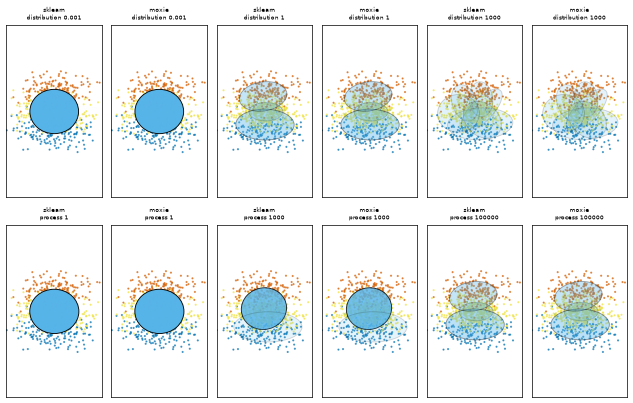

In [4]:
mx = nb.results["concentration_prior"]
fig = plt.figure(figsize=(10, 6.4), dpi=64)
gs = gridspec.GridSpec(2, 6)
for row, (kind, _, priors) in enumerate(estimators):
    for k, prior in enumerate(priors):
        for side, (label, weights, mu, cov) in enumerate([
                ("sklearn", sk[(kind, k)]["weights"], sk[(kind, k)]["means"], sk[(kind, k)]["cov"]),
                ("moxie", mx[f"weights{kind}{k}"], mx[f"means{kind}{k}"], mx[f"cov{kind}{k}"])]):
            ax = plt.subplot(gs[row, 2 * k + side])
            ax.scatter(X[:, 0], X[:, 1], s=2, color=colors[y], alpha=0.6)
            plot_ellipses(ax, weights, mu, cov)
            ax.set_xlim(-2.0, 2.0); ax.set_ylim(-3.0, 3.0); ax.set_xticks(()); ax.set_yticks(())
            ax.set_title(f"{label}\n{kind[10:]} {prior:g}", fontsize=7)
plt.tight_layout(); plt.show()

moxie_nb.side_by_side(
    sklearn=np.array([sk[(kind, k)]["weights"] for kind, _, p in estimators for k in range(3)]),
    moxie=np.array([mx[f"weights{kind}{k}"] for kind, _, p in estimators for k in range(3)]))

reason = ("Float64, identical uniform draws; up to 1500 variational iterations at tol=1e-3 amplify "
          "summation-order rounding (~1e-16/step); pinned parity uses rtol 1e-9")
for kind, _, priors in estimators:
    for k, prior in enumerate(priors):
        s, tag, name = sk[(kind, k)], f"{kind}{k}", f"{kind} {prior:g}"
        nb.compare(f"{name}: n_iter_", s["n_iter"], mx["n_iter" + tag][0], exact=True)
        nb.compare(f"{name}: converged_", float(s["converged"]), mx["converged" + tag][0], exact=True)
        for key, rtol, atol in [("weights", 1e-8, 1e-11), ("means", 1e-8, 1e-11), ("cov", 1e-8, 1e-11),
                                ("prec_chol", 1e-8, 1e-10), ("mean_precision", 1e-8, 1e-11),
                                ("dof", 1e-8, 1e-11), ("mean_prior", 1e-12, 1e-14), ("cov_prior", 1e-12, 1e-14),
                                ("proba", 1e-7, 1e-10), ("score_samples", 1e-8, 1e-10)]:
            nb.compare(f"{name}: {key}", s[key], mx[key + tag], rtol=rtol, atol=atol, reason=reason)
        parts = [mx[f"wc{tag}_{p}"] for p in range(2 if kind == "dirichlet_process" else 1)]
        nb.compare(f"{name}: weight_concentration_", s["wc"], np.vstack(parts), rtol=1e-8, atol=1e-10, reason=reason)
        nb.compare(f"{name}: degrees_of_freedom_prior_", s["dof_prior"], mx["dof_prior" + tag][0], exact=True)
        nb.compare(f"{name}: lower_bound_", s["lower_bound"], mx["lower_bound" + tag][0], rtol=1e-10, reason=reason)
        nb.compare(f"{name}: score", s["score"], mx["score" + tag][0], rtol=1e-9, reason=reason)
        nb.compare(f"{name}: predict", s["pred"], mx["pred" + tag], exact=True)

# sample(): component counts come from the same multinomial draw; coordinates are compared through
# their Mahalanobis norms under the drawing component (SVD factor orientation may differ).
nb.compare("sample labels", labels, mx["sample_labels"], exact=True)
def norms(points, labels, est_means, est_cov):
    d = points - est_means[labels]
    prec = np.linalg.inv(est_cov)[labels]
    return np.einsum("ni,nij,nj->n", d, prec, d)
nb.compare("sample Mahalanobis norms", norms(points, labels, last.means_, last.covariances_),
           norms(mx["sample_points"], mx["sample_labels"].astype(int), last.means_, last.covariances_),
           rtol=1e-6, atol=1e-9,
           reason="same standard-normal draws through a different square-root factor of the same covariance; "
                  "the norm is factor-invariant, up to the fit's 1e-8 parameter agreement")
nb.compare("sample points dtype float64", "float64", str(mx["sample_points"].dtype), exact=True)
nb.compare("clone of fitted model is unfitted", 0.0, mx["clone_fitted"][0], exact=True)
nb.note("weight_concentration_ container", "ADAPTED",
        "tuple (a, b) / array in sklearn; List of two arrays / one array in Moxie")
nb.note("sample coordinates", "ADAPTED",
        "full-covariance draws use an SVD factor whose orientation may differ from NumPy; labels and norms match")

In [5]:
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
dirichlet_distribution 0.001: n_iter_,PASS,(),(),,,exact,0 mismatches,
dirichlet_distribution 0.001: converged_,PASS,(),(),,,exact,0 mismatches,
dirichlet_distribution 0.001: weights,PASS,"(6,)","(6,)",1.07e-14,3.48e-12,"rtol=1e-08, atol=1e-11",,"Float64, identical uniform draws; up to 1500 variational iterations at tol=1e-3 amplify summation-order rounding (~1e-16/step); pinned parity uses rtol 1e-9"
dirichlet_distribution 0.001: means,PASS,"(6, 2)","(6, 2)",4.15e-13,4.6e-12,"rtol=1e-08, atol=1e-11",,"Float64, identical uniform draws; up to 1500 variational iterations at tol=1e-3 amplify summation-order rounding (~1e-16/step); pinned parity uses rtol 1e-9"
dirichlet_distribution 0.001: cov,PASS,"(6, 2, 2)","(6, 2, 2)",1.4e-12,1.3e-11,"rtol=1e-08, atol=1e-11",,"Float64, identical uniform draws; up to 1500 variational iterations at tol=1e-3 amplify summation-order rounding (~1e-16/step); pinned parity uses rtol 1e-9"
dirichlet_distribution 0.001: prec_chol,PASS,"(6, 2, 2)","(6, 2, 2)",1.91e-12,1.31e-11,"rtol=1e-08, atol=1e-10",,"Float64, identical uniform draws; up to 1500 variational iterations at tol=1e-3 amplify summation-order rounding (~1e-16/step); pinned parity uses rtol 1e-9"
dirichlet_distribution 0.001: mean_precision,PASS,"(6,)","(6,)",9.55e-12,2.69e-12,"rtol=1e-08, atol=1e-11",,"Float64, identical uniform draws; up to 1500 variational iterations at tol=1e-3 amplify summation-order rounding (~1e-16/step); pinned parity uses rtol 1e-9"
dirichlet_distribution 0.001: dof,PASS,"(6,)","(6,)",9.55e-12,2.01e-12,"rtol=1e-08, atol=1e-11",,"Float64, identical uniform draws; up to 1500 variational iterations at tol=1e-3 amplify summation-order rounding (~1e-16/step); pinned parity uses rtol 1e-9"
dirichlet_distribution 0.001: mean_prior,PASS,"(2,)","(2,)",0,0,"rtol=1e-12, atol=1e-14",,"Float64, identical uniform draws; up to 1500 variational iterations at tol=1e-3 amplify summation-order rounding (~1e-16/step); pinned parity uses rtol 1e-9"
dirichlet_distribution 0.001: cov_prior,PASS,"(2, 2)","(2, 2)",4.44e-16,6.37e-15,"rtol=1e-12, atol=1e-14",,"Float64, identical uniform draws; up to 1500 variational iterations at tol=1e-3 amplify summation-order rounding (~1e-16/step); pinned parity uses rtol 1e-9"
